# Chapter 18 · Hawkes processes and limit order books: interactive demos

Companion to Chapter 18 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/18-hawkes.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Everything here runs on simulated data. Section 5 explains how to run the same analysis on a LOBSTER message file
of your own; no data are downloaded.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import pathlib
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from ieor222 import hawkes as H
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

GREEN = PALETTE[2]
use_style()

## 1. Simulation by thinning

A Hawkes process with exponential kernel $\varphi(t)=\alpha\beta e^{-\beta t}$: every event raises the intensity by
$\alpha\beta$, and the extra intensity decays at rate $\beta$. Ogata's algorithm (Proposition 18.8) proposes candidates
at the current intensity, which bounds the future intensity until the next event, and keeps each with probability
$\lambda(s)/M$. Below: one path, its intensity, and the exact mean intensity $\mathbb E[\lambda(t)]$ of the process started
empty (Proposition 18.6), which tends to $\mu/(1-\alpha)$ when $\alpha<1$ and grows without bound when $\alpha\ge1$.

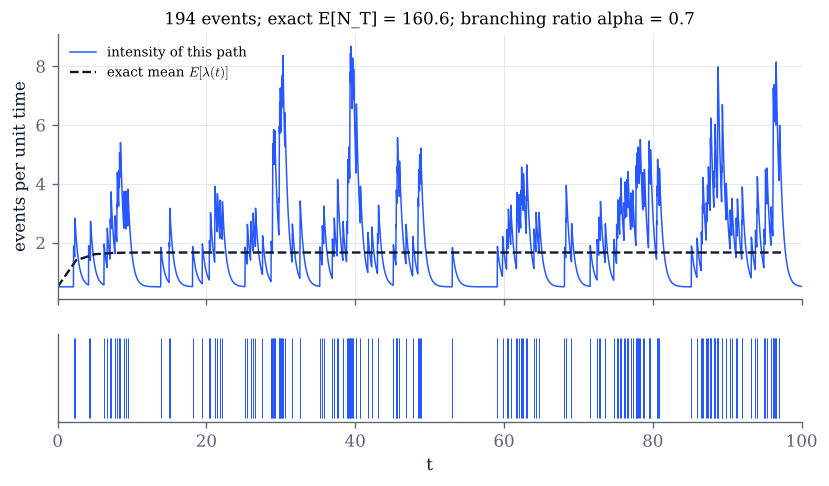

In [2]:
def thinning(mu=0.5, alpha=0.7, beta=2.0, T=100.0, seed=1):
    t, k = H.simulate_ogata(T, mu, alpha, beta, seed=seed, max_events=200_000)
    grid = np.linspace(0, T, 4000)
    lam = H.intensity_on_grid(grid, t, k, mu, alpha, beta)[:, 0]
    m, EN = H.exp_hawkes_mean(grid[::100], mu, alpha, beta)
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(8, 4.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    ax.plot(grid, lam, color=COBALT, lw=0.9, label="intensity of this path")
    ax.plot(grid[::100], m[:, 0], color=INK, lw=1.4, ls="--", label=r"exact mean $E[\lambda(t)]$")
    ax.set(ylabel="events per unit time",
           title=f"{t.size} events; exact E[N_T] = {EN[-1, 0]:.1f}; branching ratio alpha = {alpha}")
    ax.legend(fontsize=8)
    ax2.vlines(t, 0, 1, color=COBALT, lw=0.6)
    ax2.set(yticks=[], xlabel="t", xlim=(0, T))
    ax2.grid(False)
    plt.show()

thinning()

In [3]:
# Explore: push alpha towards 1 and beyond, and change the decay beta.
interact(thinning,
         mu=FloatSlider(value=0.5, min=0.05, max=2.0, step=0.05, continuous_update=False, description="μ"),
         alpha=FloatSlider(value=0.7, min=0.0, max=1.1, step=0.02, continuous_update=False, description="α"),
         beta=FloatSlider(value=2.0, min=0.2, max=10.0, step=0.1, continuous_update=False, description="β"),
         T=FloatSlider(value=100.0, min=20.0, max=500.0, step=20.0, continuous_update=False, description="T"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 2. The same process as a branching structure

Proposition 18.7: immigrants arrive as a Poisson process of rate $\mu$, and every event has a Poisson($\alpha$) number of
children at exponential lags; the superposition is the Hawkes process. Each row below is one generation. With
$\alpha$ close to one, a single immigrant can start a long cascade.

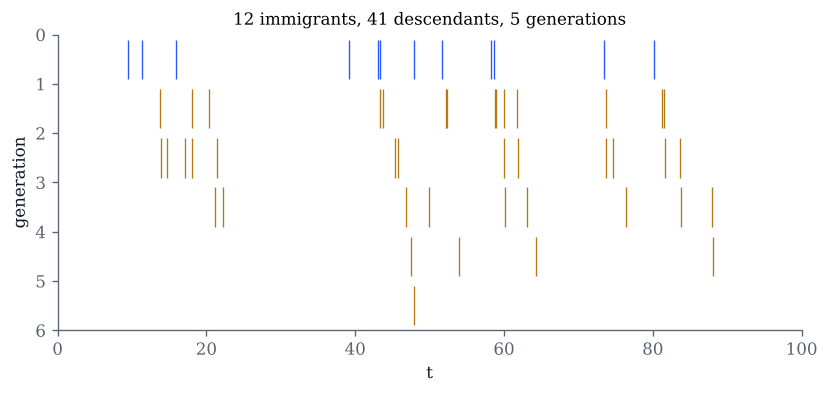

In [4]:
def branching(mu=0.2, alpha=0.8, beta=1.0, T=100.0, seed=3):
    t, k, g = H.simulate_branching(T, [mu], [[alpha]], H.exponential_lags(beta), seed=seed, return_generation=True)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    gmax = int(g.max()) if g.size else 0
    for gen in range(gmax + 1):
        sel = g == gen
        ax.vlines(t[sel], gen + 0.1, gen + 0.9, color=COBALT if gen == 0 else GOLD, lw=0.8)
    ax.set(xlim=(0, T), ylim=(gmax + 1, 0), xlabel="t", ylabel="generation",
           title=f"{np.sum(g == 0)} immigrants, {np.sum(g > 0)} descendants, {gmax} generations")
    ax.grid(False)
    plt.show()

branching()

In [5]:
interact(branching,
         mu=FloatSlider(value=0.2, min=0.02, max=1.0, step=0.02, continuous_update=False, description="μ"),
         alpha=FloatSlider(value=0.8, min=0.0, max=0.98, step=0.02, continuous_update=False, description="α"),
         beta=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="β"),
         T=FloatSlider(value=100.0, min=20.0, max=400.0, step=20.0, continuous_update=False, description="T"),
         seed=IntSlider(value=3, min=0, max=100, continuous_update=False, description="seed"));

## 3. Maximum likelihood and the time-change test

Proposition 18.9: the log-likelihood $\sum_k\log\lambda(t_k)-\int_0^T\lambda$ costs $O(n)$ for exponential kernels, and
standard errors come from the inverse observed information. Theorem 18.10: under the right model, the transformed gaps
$\Lambda(t_k)-\Lambda(t_{k-1})$ are i.i.d. Exp(1). Choose how the data are generated: by the exponential model itself,
or by a Hawkes process with a heavy-tailed kernel $\alpha\,\tau^{a}/(\tau+t)^{1+a}$, $a=1.5$, which the exponential
model can only approximate. The fit is always the exponential model, and its test is compared with a Poisson fit.

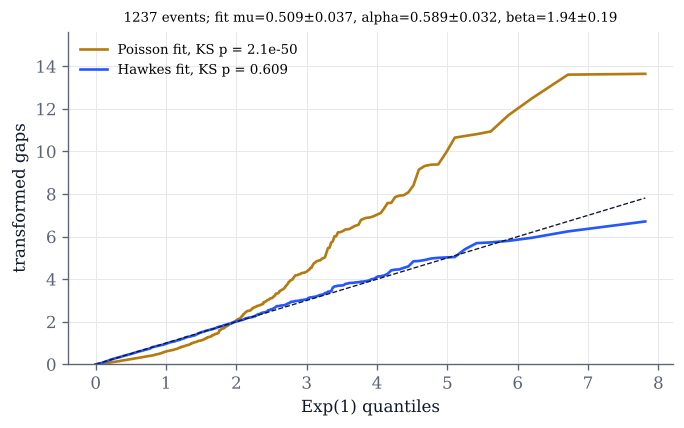

In [6]:
def fit_and_test(T=1000.0, alpha=0.6, data="exponential kernel", seed=21):
    mu, beta = 0.5, 2.0
    if data == "exponential kernel":
        t, _ = H.simulate_ogata(T, mu, alpha, beta, seed=seed)
    else:   # Lomax kernel with tail exponent 1.5 and mean lag 1/beta: same branching ratio
        tau = 0.5 / beta
        t, _ = H.simulate_branching(T, [mu], [[alpha]], H.lomax_lags(1.5, tau), seed=seed)
    f = H.fit_exp_hawkes(t, T)
    gaps_h = H.time_changed_gaps(t, np.zeros(t.size, int), *f["theta"])[0]
    gaps_p = np.diff(np.concatenate([[0.0], t])) * t.size / T
    q = (np.arange(1, t.size + 1) - 0.5) / t.size
    ex = -np.log1p(-q)
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.plot(ex, np.sort(gaps_p), color=GOLD, label=f"Poisson fit, KS p = {H.ks_exponential(gaps_p)[1]:.1e}")
    ax.plot(ex, np.sort(gaps_h), color=COBALT, label=f"Hawkes fit, KS p = {H.ks_exponential(gaps_h)[1]:.3f}")
    ax.plot([0, ex.max()], [0, ex.max()], color=INK, lw=0.8, ls="--")
    ax.set(xlabel="Exp(1) quantiles", ylabel="transformed gaps", ylim=(0, 2 * ex.max()))
    ax.legend(fontsize=8)
    th, se = f["theta"], f["se"]
    ax.set_title(f"{t.size} events; fit mu={th[0]:.3f}±{se[0]:.3f}, alpha={th[1]:.3f}±{se[1]:.3f}, "
                 f"beta={th[2]:.2f}±{se[2]:.2f}", fontsize=8)
    plt.show()

fit_and_test()

In [7]:
# Explore: with the heavy-tailed data, how long must the sample be before the test rejects the exponential model?
interact(fit_and_test,
         T=FloatSlider(value=1000.0, min=200.0, max=8000.0, step=200.0, continuous_update=False, description="T"),
         alpha=FloatSlider(value=0.6, min=0.1, max=0.9, step=0.05, continuous_update=False, description="α"),
         data=Dropdown(options=["exponential kernel", "heavy-tailed kernel"], value="exponential kernel", description="data"),
         seed=IntSlider(value=21, min=0, max=100, continuous_update=False, description="seed"));

## 4. A toy limit order book

Six event types (market buy and sell, limit orders at the bid and the ask, cancellations at the bid and the ask) with
the branching matrix of `lob_toy_model`. The slider multiplies the whole matrix $G$ by a factor, which moves its spectral
radius. Left: simulated rates against $(I-G)^{-1}\mu$ (Proposition 18.6). Middle: the mid-price of the queue mechanism
of Section 18.5. Right: the branching matrix estimated by maximum likelihood with known decays, a concave problem
(Proposition 18.9(iii)).

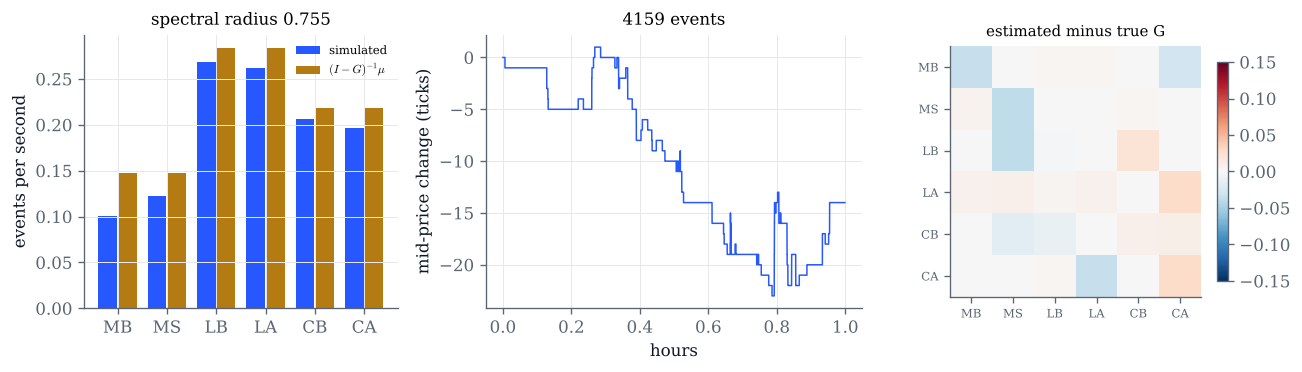

In [8]:
def order_book(scale=1.0, hours=1.0, seed=2026):
    mu, G0, beta = H.lob_toy_model()
    G = scale * G0
    T = 3600.0 * hours
    rho = H.spectral_radius(G)
    t, k = H.simulate_ogata(T, mu, G, beta, seed=seed, max_events=400_000)
    emp = np.bincount(k, minlength=6) / T
    fig, axs = plt.subplots(1, 3, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 1.2, 1]})
    x = np.arange(6)
    axs[0].bar(x - 0.2, emp, width=0.38, color=COBALT, label="simulated")
    if rho < 1:
        axs[0].bar(x + 0.2, H.mean_intensity(mu, G), width=0.38, color=GOLD, label=r"$(I-G)^{-1}\mu$")
    axs[0].set_xticks(x, H.LOB_TYPES)
    axs[0].set(ylabel="events per second", title=f"spectral radius {rho:.3f}")
    axs[0].legend(fontsize=7)
    mid = H.lob_mid_price(t, k)
    axs[1].step(t / 3600, mid / 0.01, where="post", color=COBALT, lw=0.9)
    axs[1].set(xlabel="hours", ylabel="mid-price change (ticks)", title=f"{t.size} events")
    if t.size > 50:
        fit = H.fit_fixed_beta(t, k, T, beta, 6)
        im = axs[2].imshow(fit["alpha"] - G, cmap="RdBu_r", vmin=-0.15, vmax=0.15)
        axs[2].set_xticks(x, H.LOB_TYPES, fontsize=7)
        axs[2].set_yticks(x, H.LOB_TYPES, fontsize=7)
        axs[2].set_title("estimated minus true G", fontsize=9)
        axs[2].grid(False)
        fig.colorbar(im, ax=axs[2], shrink=0.8)
    fig.tight_layout()
    plt.show()

order_book()

In [9]:
interact(order_book,
         scale=FloatSlider(value=1.0, min=0.0, max=1.3, step=0.05, continuous_update=False, description="G factor"),
         hours=FloatSlider(value=1.0, min=0.25, max=4.0, step=0.25, continuous_update=False, description="hours"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 5. Real order book data: how to plug them in

The analysis of Section 4 runs unchanged on message data in the
[LOBSTER](https://lobsterdata.com) format, which reconstructs Nasdaq order books; LOBSTER offers free sample files on its
website, and its terms decide how you may use them. A message file is a CSV with the columns
(time in seconds after midnight, event type, order id, size, price, direction). `lobster_to_events` keeps new limit orders
(type 1), cancellations (types 2 and 3) and visible executions (type 4), codes them as the six event types of the notes,
and merges messages of one market order that share a time stamp. Set `LOBSTER_FILE` below to the path of a message file
on your machine; otherwise a synthetic path from the toy model stands in. The decays are not estimated here; try a few
values, or fit them per type with `fit_exp_hawkes`.

In [10]:
LOBSTER_FILE = None   # e.g. "AAPL_2012-06-21_34200000_57600000_message_10.csv"

if LOBSTER_FILE and pathlib.Path(LOBSTER_FILE).exists():
    message = np.loadtxt(LOBSTER_FILE, delimiter=",")
    times, types = H.lobster_to_events(message)
    source = pathlib.Path(LOBSTER_FILE).name
else:
    mu, G, beta = H.lob_toy_model()
    times, types = H.simulate_ogata(1800.0, mu, G, beta, seed=7)
    source = "synthetic toy model (no LOBSTER file given)"
T = float(times[-1]) + 1e-9
for b in (1.0, 4.0, 20.0):
    fit = H.fit_fixed_beta(times, types, T, b, 6)
    pv = [H.ks_exponential(g)[1] for g in H.time_changed_gaps(times, types, fit["mu"], fit["alpha"], b)]
    print(f"{source}: decay {b:5.1f}/s  log-likelihood {fit['loglik']:12.1f}  spectral radius of G-hat "
          f"{H.spectral_radius(fit['alpha']):.3f}  smallest KS p-value {min(pv):.3g}")

synthetic toy model (no LOBSTER file given): decay   1.0/s  log-likelihood      -3112.4  spectral radius of G-hat 0.802  smallest KS p-value 1.23e-08
synthetic toy model (no LOBSTER file given): decay   4.0/s  log-likelihood      -2591.8  spectral radius of G-hat 0.753  smallest KS p-value 0.565
synthetic toy model (no LOBSTER file given): decay  20.0/s  log-likelihood      -3450.3  spectral radius of G-hat 0.596  smallest KS p-value 0.00121


## 6. Nearly unstable Hawkes processes

Theorem 18.13. **Light tails:** with kernel $a_T\beta e^{-\beta t}$ and $a_T=1-\lambda/T$, the rescaled intensity
$C^T_1=(1-a_T)\lambda^T_T$ converges to the CIR process at time 1, whose law is a Gamma law. **Heavy tails:** with the kernel
$a_T\,\alpha(1+t)^{-1-\alpha}$ and the scaling of Theorem 18.13(ii), the rescaled event rate becomes rough, with
$H=\alpha-\frac12$. The variogram of the binned rate is compared with that of bin averages of a process with variogram
$|r|^{2H}$ (`binned_fbm_variogram`): bin averages flatten rough variograms at small lags.

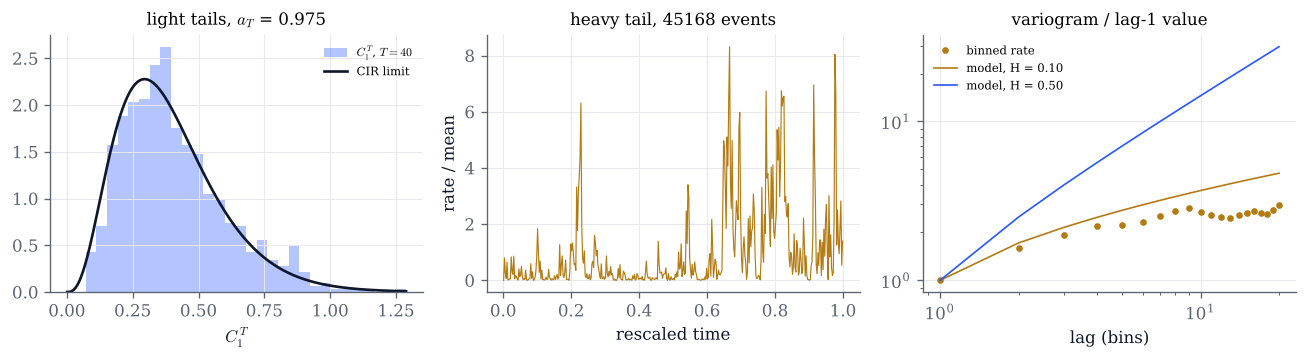

In [11]:
def nearly_unstable(T_light=40.0, tail=0.6, log10_T_heavy=5.0, seed=1):
    mu, lam, beta = 1.0, 1.0, 0.5
    C = H.nearly_unstable_light(T_light, mu, lam, beta, n_paths=800, seed=seed)
    shape, scale = H.cir_from_zero_gamma(mu, lam, 1 / beta)
    Th = 10.0 ** log10_T_heavy
    a, muT, sc = H.heavy_tail_scaling(Th, tail)
    th, _ = H.simulate_branching(Th, [muT], [[a]], H.lomax_lags(tail), seed=seed)
    nb, lags = 400, np.arange(1, 21)
    y, nv = H.binned_rates(th, Th, sc, nb)
    v = H.binned_variogram(y[nb // 5:], lags, nv)
    fig, axs = plt.subplots(1, 3, figsize=(11, 3.1))
    axs[0].hist(C, bins=30, density=True, color=COBALT, alpha=0.35, label=rf"$C^T_1$, $T={T_light:g}$")
    xs = np.linspace(1e-3, C.max(), 300)
    axs[0].plot(xs, stats.gamma(shape, scale=scale).pdf(xs), color=INK, label="CIR limit")
    axs[0].legend(fontsize=7)
    axs[0].set(xlabel=r"$C^T_1$", title=rf"light tails, $a_T$ = {1 - lam / T_light:.3f}")
    axs[1].plot((np.arange(nb) + 0.5) / nb, y / max(y.mean(), 1e-12), color=GOLD, lw=0.7)
    axs[1].set(xlabel="rescaled time", ylabel="rate / mean", title=f"heavy tail, {th.size} events")
    if np.all(v > 0):
        axs[2].plot(lags, v / v[0], "o", ms=3, color=GOLD, label="binned rate")
    for Hh, col in ((tail - 0.5, GOLD), (0.5, COBALT)):
        axs[2].plot(lags, H.binned_fbm_variogram(lags, Hh) / H.binned_fbm_variogram(1, Hh), color=col, lw=1,
                    label=f"model, H = {Hh:.2f}")
    axs[2].set(xscale="log", yscale="log", xlabel="lag (bins)", title="variogram / lag-1 value")
    axs[2].legend(fontsize=7)
    fig.tight_layout()
    plt.show()

nearly_unstable()

In [12]:
# Explore: larger T_light brings the histogram onto the Gamma density; tail exponents near 1/2 give rougher paths.
# Heavy-tailed paths have about T^(2 alpha) events: keep log10 T moderate when alpha is large.
interact(nearly_unstable,
         T_light=FloatSlider(value=40.0, min=5.0, max=80.0, step=5.0, continuous_update=False, description="T light"),
         tail=FloatSlider(value=0.6, min=0.55, max=0.9, step=0.05, continuous_update=False, description="α (tail)"),
         log10_T_heavy=FloatSlider(value=5.0, min=3.0, max=6.0, step=0.25, continuous_update=False, description="log10 T"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $\alpha=1$. The mean intensity grows linearly instead of settling (Proposition 18.6(iii)); what does a
  single path do?
- In section 2, keep $\mu\,T$ fixed and move $\alpha$ from $0.5$ to $0.95$. How do the number of generations and the
  burstiness of the path change?
- In section 3, with heavy-tailed data and $\alpha=0.8$, how large must $T$ be before the time-change test rejects the
  exponential model? Which part of the QQ plot gives it away?
- In section 4, push the factor towards the value at which the spectral radius reaches one. What happens to the event
  rates and to the mid-price?
- In section 6, compare the heavy-tailed rate path for $\alpha=0.55$ and $\alpha=0.9$, and read the roughness off the
  variogram.